## 1. Setup

# Water Segmentation with a 3-Channel Pretrained Input (Week 2, mentor revision)

Pretrained ResNet U-Net (`segmentation-models-pytorch`) fed with exactly **3 channels**, so the ImageNet first convolution is used **unchanged** (no zero-init or averaged weights). Following the mentor's request, the model uses only the best three channels, or averages of channels, instead of 12 or 16 inputs.

The recipe that worked in the 16-channel run of `twosplitswsp.ipynb` is carried over as it is (ResNet50, BCE + Tversky loss, channel attention, EMA, 2x input upscaling, 150 epochs). The technique search is not repeated; only the choice of the 3 input channels is evaluated. Same data pipeline, features, seed and 80 / 20 split as before, so the results are comparable with the 16-channel model.

In [1]:
import os, glob, random, math, copy, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy.ndimage import uniform_filter, label as cc_label
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

try:
    import segmentation_models_pytorch as smp
except ImportError:
    %pip install -q segmentation-models-pytorch
    import segmentation_models_pytorch as smp

warnings.filterwarnings("ignore", category=UserWarning)

DATA_DIR = "/kaggle/input/datasets/shahdelsawy/sattlite-segmentation/data"
SEED = 42
BATCH_SIZE = 32
VAL_FRACTION = 0.20
EMA_DECAY = 0.99
SEEDS_EXTRA = [43, 44]
PIXEL_SIZE = 30.0

PRETRAINED_HP = dict(epochs=150, warm=3, lr_enc=3e-4, lr_dec=1e-3, rotate=True, anc_drop=0.0)
SCRATCH_HP = dict(epochs=100, warm=1, lr_enc=1e-3, lr_dec=1e-3, rotate=False, anc_drop=0.3)

# Recipe carried over from the 16-channel run of twosplitswsp.ipynb (not searched again)
FINAL_CFG = {"encoder": "resnet50"}
FINAL_RECIPE = dict(attention=True, ema=True, loss="tversky", scale=2)

# Results of that 16-channel model on the same split and seed, kept for comparison only
REFERENCE_16CH = {"val": {"iou": 0.8385, "f1": 0.9122, "precision": 0.9121, "recall": 0.9123},
                  "tta": {"iou": 0.8512, "f1": 0.9196, "precision": 0.9234, "recall": 0.9159}}

MAX_CORR = 0.8              # top-3 selection skips channels this correlated with an already chosen one
MANUAL_TOP3 = None          # e.g. ["Green", "NIR", "SWIR1"] to override the automatic top-3 selection
TOP3_ALLOW_ANCILLARY = True # False restricts the top-3 choice to optical bands and indices

BANDS = ["Coastal aerosol", "Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2",
         "QA band", "MERIT DEM", "Copernicus DEM", "ESA WorldCover", "Water occurrence"]
INDICES = ["NDWI", "MNDWI", "NDVI", "AWEI"]
ANCILLARY = ["Copernicus DEM", "Slope", "Relief", "Water occurrence", "WC water", "WC wetland"]
EXTRA = ["Slope", "Relief", "WC water", "WC wetland"]
BINARY = ["WC water", "WC wetland"]
GROUPED = ["Visible mean", "SWIR mean"]
NAMES = BANDS + INDICES + EXTRA + GROUPED


def idx(names):
    return [NAMES.index(n) for n in names]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
print(device, "| smp", smp.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
cuda | smp 0.5.0


## 2. Load data

In [2]:
image_paths = sorted(glob.glob(f"{DATA_DIR}/images/*.tif"))
label_dir = f"{DATA_DIR}/labels"

N, H, W, C = len(image_paths), 128, 128, 12
X = np.zeros((N, len(NAMES), H, W), dtype=np.float32)
Y = np.zeros((N, H, W), dtype=np.float32)

for i, path in enumerate(tqdm(image_paths)):
    name = os.path.splitext(os.path.basename(path))[0]
    img = tifffile.imread(path)
    assert img.shape == (H, W, C), img.shape
    X[i, :C] = np.nan_to_num(img.transpose(2, 0, 1))
    Y[i] = np.array(Image.open(f"{label_dir}/{name}.png")) > 0

print(N, "images", X.shape, Y.shape)

  0%|          | 0/306 [00:00<?, ?it/s]

306 images (306, 22, 128, 128) (306, 128, 128)


## 3. Data exploration

water pixels 25.98% | images without water 14.71%
MERIT DEM minimum -9999 (no-data value) | water occurrence maximum 111


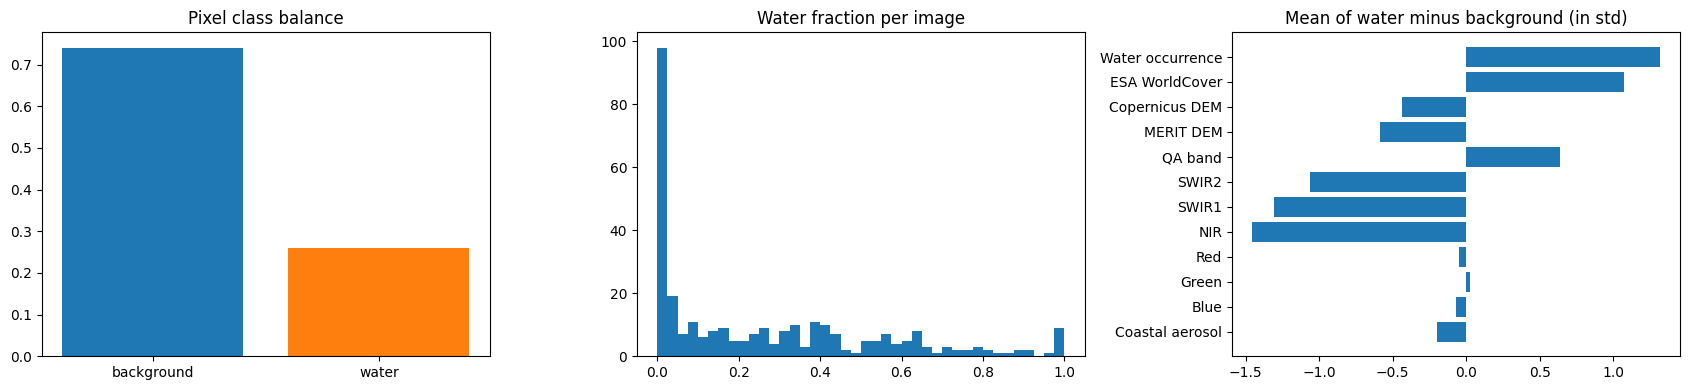

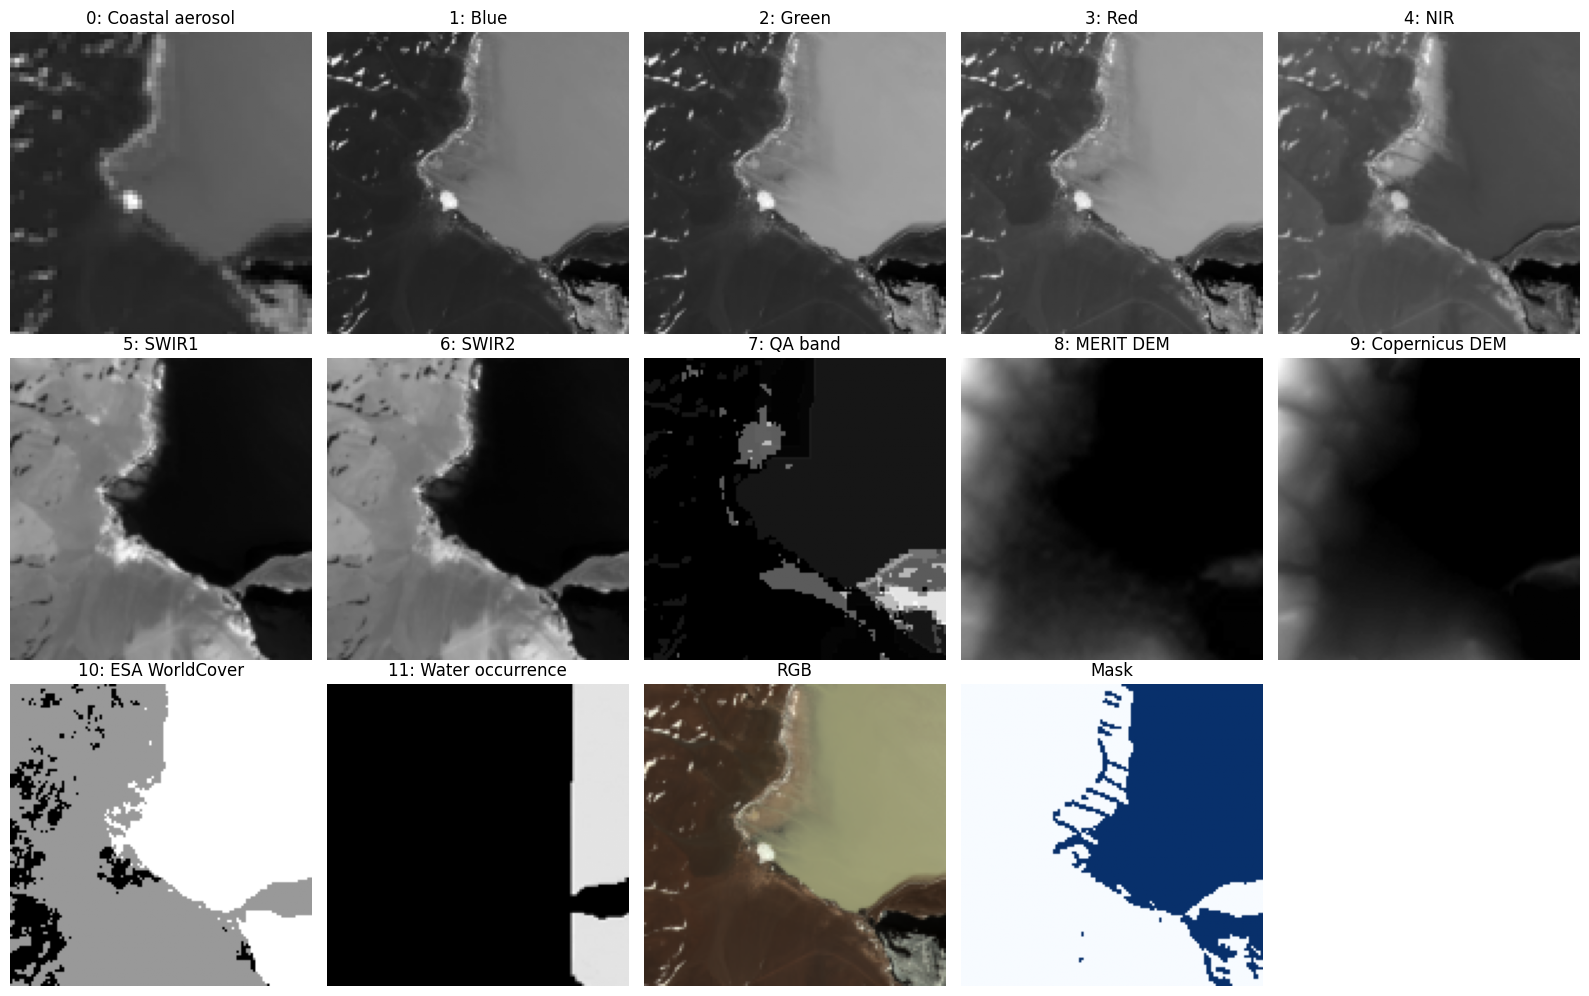

In [3]:
water_ratio = Y.mean()
per_image = Y.mean(axis=(1, 2))
print(f"water pixels {water_ratio:.2%} | images without water {(per_image == 0).mean():.2%}")
print(f"MERIT DEM minimum {X[:, 8].min():.0f} (no-data value) | water occurrence maximum {X[:, 11].max():.0f}")

separation = []
for c in range(C):
    v = np.clip(X[:, c], *np.percentile(X[:, c], [1, 99]))
    separation.append((v[Y > 0.5].mean() - v[Y < 0.5].mean()) / (v.std() + 1e-8))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(["background", "water"], [1 - water_ratio, water_ratio], color=COLORS[:2])
axes[0].set_title("Pixel class balance")
axes[1].hist(per_image, bins=40)
axes[1].set_title("Water fraction per image")
axes[2].barh(BANDS, separation)
axes[2].set_title("Mean of water minus background (in std)")
plt.tight_layout()
plt.show()

k = int(np.argmin(np.abs(per_image - 0.4)))
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for c in range(C):
    axes.flat[c].imshow(X[k, c], cmap="gray")
    axes.flat[c].set_title(f"{c}: {BANDS[c]}")
rgb = X[k, [3, 2, 1]].transpose(1, 2, 0)
axes.flat[12].imshow((rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6))
axes.flat[12].set_title("RGB")
axes.flat[13].imshow(Y[k], cmap="Blues")
axes.flat[13].set_title("Mask")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Feature engineering

| Channel | Decision |
|---|---|
| Coastal aerosol, QA band, MERIT DEM | Drop: aerosol band correlated with Blue, bit flags, near-duplicate of Copernicus DEM with a -9999 no-data value |
| Blue, Green, Red, NIR, SWIR1, SWIR2 | Keep: water absorbs NIR and SWIR, Green is needed for the water indices |
| Copernicus DEM, Water occurrence | Keep: water lies in low flat areas, occurrence is the historical water frequency |
| ESA WorldCover | One-hot water and wetland channels instead of raw class codes |
| NDWI, MNDWI, NDVI, AWEI | Add: spectral water and vegetation indices |
| Slope, Relief | Add: flatness and height above the local 15 x 15 mean |

Two more channels, **Visible mean** and **SWIR mean**, are averages of the normalized Blue/Green/Red and SWIR1/SWIR2 bands. They are built in Section 5 and used only by the group-average input.

In [4]:
def norm_diff(a, b):
    return (a - b) / (a + b + 1e-6)

green, red, nir, swir1, swir2 = (X[:, i] for i in (2, 3, 4, 5, 6))
X[:, 12] = norm_diff(green, nir)
X[:, 13] = norm_diff(green, swir1)
X[:, 14] = norm_diff(nir, red)
X[:, 15] = 4 * (green - swir1) - (0.25 * nir + 2.75 * swir2)
del green, red, nir, swir1, swir2

dem = X[:, BANDS.index("Copernicus DEM")].copy()
gy, gx = np.gradient(dem, PIXEL_SIZE, axis=(1, 2))
X[:, NAMES.index("Slope")] = np.degrees(np.arctan(np.hypot(gx, gy)))
X[:, NAMES.index("Relief")] = dem - uniform_filter(dem, size=(1, 15, 15), mode="reflect")
del dem, gx, gy

LC = np.rint(X[:, BANDS.index("ESA WorldCover")]).astype(np.int16)
X[:, NAMES.index("WC water")] = LC == 80
X[:, NAMES.index("WC wetland")] = np.isin(LC, (90, 95))

## 5. Split and normalization

Two splits: 80% train and 20% validation. Every model uses its final-epoch weights, so no epoch is picked on the validation set. The validation set still guides the choice of techniques in Stage 2 and is the reported score, so the numbers are somewhat optimistic compared with a separate test set.

In [5]:
perm = np.random.permutation(N)
n_val = int(VAL_FRACTION * N)
val_idx = perm[:n_val]
train_idx = perm[n_val:]
print("train / validation:", len(train_idx), len(val_idx))

channel_stats = {}
for c in range(X.shape[1]):
    if NAMES[c] in GROUPED:
        continue
    if NAMES[c] in BINARY:
        channel_stats[NAMES[c]] = (0, 1, 0, 1)
        continue
    low, high = np.percentile(X[train_idx[:500], c], [1, 99])
    train_values = np.clip(X[train_idx, c], low, high)
    mean, std = train_values.mean(), train_values.std() + 1e-8
    X[:, c] = (np.clip(X[:, c], low, high) - mean) / std
    channel_stats[NAMES[c]] = (low, high, mean, std)

# Averaged channels: mean of the already normalized bands, then re-standardized with training statistics
GROUPS = {"Visible mean": ["Blue", "Green", "Red"], "SWIR mean": ["SWIR1", "SWIR2"]}
for name, members in GROUPS.items():
    c = NAMES.index(name)
    X[:, c] = X[:, idx(members)].mean(axis=1)
    mean, std = X[train_idx, c].mean(), X[train_idx, c].std() + 1e-8
    X[:, c] = (X[:, c] - mean) / std
    channel_stats[name] = (np.nan, np.nan, mean, std)

pd.DataFrame.from_dict(channel_stats, orient="index", columns=["low", "high", "mean", "std"]).to_csv("normalization_stats_3ch.csv")

gt_val = Y[val_idx] > 0.5

train / validation: 245 61


## 6. Channel importance

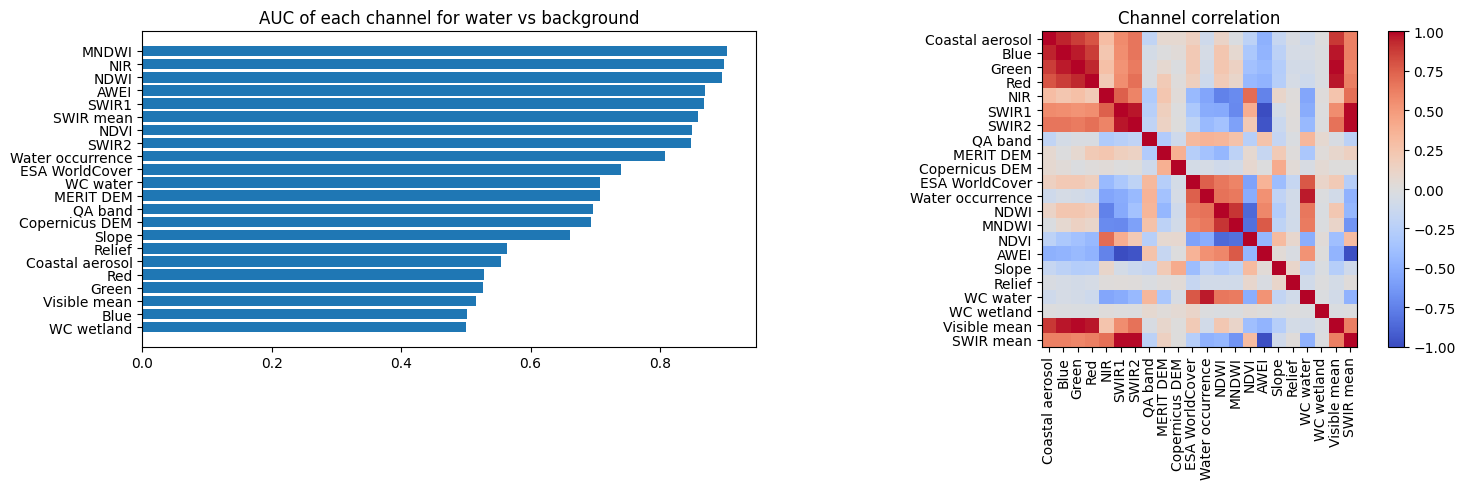

AUC ranking of the candidate pool (training pixels only):
  MNDWI              AUC 0.904   <- selected
  NIR                AUC 0.899   <- selected
  NDWI               AUC 0.895
  AWEI               AUC 0.870   <- selected
  SWIR1              AUC 0.867
  NDVI               AUC 0.850
  SWIR2              AUC 0.848
  Water occurrence   AUC 0.808
  WC water           AUC 0.707
  Copernicus DEM     AUC 0.694
  Slope              AUC 0.661
  Relief             AUC 0.564
  Red                AUC 0.528
  Green              AUC 0.526
  Blue               AUC 0.502
  WC wetland         AUC 0.501
top-3 input channels: ['MNDWI', 'NIR', 'AWEI']


In [6]:
rng = np.random.default_rng(0)
sample_images = rng.choice(train_idx, size=min(300, len(train_idx)), replace=False)
pixel_ids = rng.integers(0, H * W, size=(len(sample_images), 400))
xs = np.concatenate([X[i].reshape(len(NAMES), -1)[:, p] for i, p in zip(sample_images, pixel_ids)], axis=1).T
ys = np.concatenate([Y[i].reshape(-1)[p] for i, p in zip(sample_images, pixel_ids)])

auc = np.array([max(a, 1 - a) for a in (roc_auc_score(ys, xs[:, c]) for c in range(len(NAMES)))])
order = np.argsort(auc)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh([NAMES[i] for i in order], auc[order])
axes[0].set_title("AUC of each channel for water vs background")
im = axes[1].imshow(np.corrcoef(xs.T), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(NAMES)))
axes[1].set_xticklabels(NAMES, rotation=90)
axes[1].set_yticks(range(len(NAMES)))
axes[1].set_yticklabels(NAMES)
axes[1].set_title("Channel correlation")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

core = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"] + INDICES
SIXTEEN = core + ["Copernicus DEM", "Slope", "Relief", "Water occurrence", "WC water", "WC wetland"]
FEATURE_SETS = {"plus_terrain_landcover": idx(SIXTEEN)}   # the 16 channels, used by the scratch U-Net baseline

pool = idx(SIXTEEN) if TOP3_ALLOW_ANCILLARY else idx(core)
corr = np.corrcoef(xs.T)


def select_top3(pool, auc, corr, max_corr):
    ranked = sorted(pool, key=lambda c: -auc[c])
    chosen = []
    for c in ranked:
        if all(abs(corr[c, k]) < max_corr for k in chosen):
            chosen.append(c)
        if len(chosen) == 3:
            return chosen
    return chosen + [c for c in ranked if c not in chosen][:3 - len(chosen)]


TOP3 = MANUAL_TOP3 or [NAMES[c] for c in select_top3(pool, auc, corr, MAX_CORR)]
print("AUC ranking of the candidate pool (training pixels only):")
for c in sorted(pool, key=lambda c: -auc[c]):
    print(f"  {NAMES[c]:18s} AUC {auc[c]:.3f}{'   <- selected' if NAMES[c] in TOP3 else ''}")
print("top-3 input channels:", TOP3)

INPUTS = [
    dict(name="RGB (control)", channels=["Red", "Green", "Blue"]),
    dict(name="Top-3 by AUC", channels=TOP3),
    dict(name="Green, NIR, SWIR1", channels=["Green", "NIR", "SWIR1"]),
    dict(name="Group averages", channels=["Visible mean", "NIR", "SWIR mean"]),
]

## 7. Pretrained encoder with a 3-channel input

ResNet encoders are pretrained on 3-channel ImageNet photos. The 12/16-channel version rewrote the first convolution (average or zero-init weights), which the mentor flagged as not good enough. Here the network receives exactly **3 channels** and the pretrained first convolution is kept **unchanged**, so the question becomes which 3 channels to feed. The input channels are compared in Section 10:

- **RGB (control):** Red, Green, Blue, the input the filters were trained for
- **Top-3 by AUC:** the three channels with the highest water-vs-background AUC on training pixels, skipping any channel whose absolute correlation with an already chosen one is at least `MAX_CORR` (Section 6)
- **Green, NIR, SWIR1:** the bands behind NDWI and MNDWI, since water reflects Green and absorbs NIR and SWIR
- **Group averages:** mean of the normalized visible bands, NIR, and mean of SWIR1 and SWIR2, which compresses 6 bands into 3 without learned weights

In [7]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=4, identity_init=True):
        super().__init__()
        hidden = max(channels // reduction, 2)
        self.fc = nn.Sequential(nn.Linear(channels, hidden), nn.ReLU(), nn.Linear(hidden, channels), nn.Sigmoid())
        if identity_init:
            nn.init.zeros_(self.fc[2].weight)
            nn.init.constant_(self.fc[2].bias, 3.0)

    def forward(self, x):
        return x * self.fc(x.mean(dim=(2, 3)))[:, :, None, None]


class WithAttention(nn.Module):
    def __init__(self, net, channels):
        super().__init__()
        self.attn, self.net = ChannelAttention(channels), net

    @property
    def encoder(self):
        return self.net.encoder

    def forward(self, x):
        return self.net(self.attn(x))


class Upscaled(nn.Module):
    def __init__(self, net, scale):
        super().__init__()
        self.net, self.scale = net, scale

    @property
    def encoder(self):
        return self.net.encoder

    def forward(self, x):
        return F.avg_pool2d(self.net(F.interpolate(x, scale_factor=self.scale, mode="bilinear", align_corners=False)), self.scale)


def build_model(cfg, channels, recipe):
    try:
        net = smp.Unet(encoder_name=cfg["encoder"], encoder_weights="imagenet", in_channels=3, classes=1)
    except Exception as e:
        raise RuntimeError("Could not download ImageNet weights. Turn internet on and run again.") from e
    assert len(channels) == 3, "the pretrained first convolution expects exactly 3 channels"
    if recipe["scale"] > 1:
        net = Upscaled(net, recipe["scale"])
    return WithAttention(net, len(channels)) if recipe["attention"] else net


m = build_model(FINAL_CFG, [0, 1, 2], FINAL_RECIPE)
first = next(mod for mod in m.encoder.modules() if isinstance(mod, nn.Conv2d))
print(f"first conv {tuple(first.weight.shape)} (pretrained, unchanged) | output {tuple(m(torch.randn(2, 3, H, W)).shape)} | {sum(p.numel() for p in m.parameters()) / 1e6:.1f} M parameters")
del m

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

first conv (64, 3, 7, 7) (pretrained, unchanged) | output (2, 1, 128, 128) | 32.5 M parameters


## 8. Training utilities

In [8]:
def bce_dice(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(1, 2, 3))
    return bce + 1 - ((2 * inter + 1) / (prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) + 1)).mean()


def bce_tversky(logits, target, alpha=0.3, beta=0.7):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    tp = (prob * target).sum(dim=(1, 2, 3))
    fp = (prob * (1 - target)).sum(dim=(1, 2, 3))
    fn = ((1 - prob) * target).sum(dim=(1, 2, 3))
    return bce + 1 - ((tp + 1) / (tp + alpha * fp + beta * fn + 1)).mean()


LOSSES = {"dice": bce_dice, "tversky": bce_tversky}


class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        for e, p in zip(self.module.parameters(), model.parameters()):
            e.lerp_(p, 1 - d)
        for e, b in zip(self.module.buffers(), model.buffers()):
            e.copy_(b)


class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)


class ScratchUNet(nn.Module):
    def __init__(self, in_channels, base=32):
        super().__init__()
        b = base
        self.attn = ChannelAttention(in_channels, identity_init=False)
        self.enc1, self.enc2 = DoubleConv(in_channels, b), DoubleConv(b, 2 * b)
        self.enc3, self.enc4 = DoubleConv(2 * b, 4 * b), DoubleConv(4 * b, 8 * b)
        self.bottleneck = DoubleConv(8 * b, 16 * b)
        self.pool = nn.MaxPool2d(2)
        self.up4, self.dec4 = nn.ConvTranspose2d(16 * b, 8 * b, 2, stride=2), DoubleConv(16 * b, 8 * b)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, stride=2), DoubleConv(8 * b, 4 * b)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, stride=2), DoubleConv(4 * b, 2 * b)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * b, b, 2, stride=2), DoubleConv(2 * b, b)
        self.head = nn.Conv2d(b, 1, 1)

    def forward(self, x):
        e1 = self.enc1(self.attn(x))
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        x = self.bottleneck(self.pool(e4))
        x = self.dec4(torch.cat([self.up4(x), e4], dim=1))
        x = self.dec3(torch.cat([self.up3(x), e3], dim=1))
        x = self.dec2(torch.cat([self.up2(x), e2], dim=1))
        x = self.dec1(torch.cat([self.up1(x), e1], dim=1))
        return self.head(x)


def make_loader(indices, channels, shuffle):
    x = torch.from_numpy(X[np.ix_(indices, channels)])
    y = torch.from_numpy(Y[indices]).unsqueeze(1)
    return DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=shuffle)


@torch.no_grad()
def predict_tensor(model, x):
    model.eval()
    return torch.cat([torch.sigmoid(model(b.to(device))).cpu() for b in x.split(BATCH_SIZE)]).squeeze(1).numpy()


def predict_proba(model, indices, channels):
    return predict_tensor(model, torch.from_numpy(X[np.ix_(indices, channels)]))


def scores(tp, fp, fn):
    precision, recall = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return {"iou": tp / (tp + fp + fn + 1e-9), "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall + 1e-9)}


def metrics(prob, gt, threshold=0.5):
    pred = prob > threshold
    return scores((pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum())


@torch.no_grad()
def val_pass(model, loader, loss_fn):
    model.eval()
    tp = fp = fn = tn = loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss += loss_fn(logits, y).item() * len(x)
        pred, gt = logits > 0, y > 0.5
        tp += (pred & gt).sum().item()
        fp += (pred & ~gt).sum().item()
        fn += (~pred & gt).sum().item()
        tn += (~pred & ~gt).sum().item()
    s = scores(tp, fp, fn)
    return {"val_loss": loss / len(loader.dataset), "val_acc": (tp + tn) / (tp + fp + fn + tn), "val_iou": s["iou"], "val_f1": s["f1"]}


def train(cfg, recipe, tag, seed=SEED):
    is_scratch = cfg["encoder"] == "scratch"
    hp = SCRATCH_HP if is_scratch else PRETRAINED_HP
    channels = FEATURE_SETS[cfg["feature_set"]] if is_scratch else idx(cfg["channels"])
    train_loader, val_loader = make_loader(train_idx, channels, True), make_loader(val_idx, channels, False)
    random.seed(seed)
    torch.manual_seed(seed)
    model = (ScratchUNet(len(channels)) if is_scratch else build_model(cfg, channels, recipe)).to(device)
    ema = EMA(model, EMA_DECAY) if recipe["ema"] else None
    eval_model = ema.module if ema else model
    loss_fn = LOSSES[recipe["loss"]]
    anc = [j for j, c in enumerate(channels) if NAMES[c] in ANCILLARY]

    if hasattr(model, "encoder"):
        enc = list(model.encoder.parameters())
        enc_ids = {id(p) for p in enc}
        groups = [{"params": enc, "lr": hp["lr_enc"]}, {"params": [p for p in model.parameters() if id(p) not in enc_ids], "lr": hp["lr_dec"]}]
    else:
        groups = [{"params": list(model.parameters()), "lr": hp["lr_dec"]}]
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    warm, epochs = hp["warm"], hp["epochs"]
    cosine = lambda e: 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (e - warm) / (epochs - warm)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda e: (e + 1) / warm if e < warm else cosine(e))

    history, step = [], 0
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = tp = fp = fn = tn = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if random.random() < 0.5:
                x, y = x.flip(3), y.flip(3)
            if random.random() < 0.5:
                x, y = x.flip(2), y.flip(2)
            if hp["rotate"]:
                k = random.randint(0, 3)
                x, y = torch.rot90(x, k, (2, 3)), torch.rot90(y, k, (2, 3))
            if hp["anc_drop"]:
                drop = torch.rand(len(x), 1, 1, 1, device=x.device) < hp["anc_drop"]
                x[:, anc] = x[:, anc] * (~drop)
            optimizer.zero_grad()
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            if ema:
                ema.update(model, step)
            step += 1
            loss_sum += loss.item() * len(x)
            pred, gt = logits > 0, y > 0.5
            tp += (pred & gt).sum().item()
            fp += (pred & ~gt).sum().item()
            fn += (~pred & gt).sum().item()
            tn += (~pred & ~gt).sum().item()
        scheduler.step()

        s = scores(tp, fp, fn)
        history.append({"epoch": epoch, "train_loss": loss_sum / len(train_idx), "train_acc": (tp + tn) / (tp + fp + fn + tn),
                        "train_iou": s["iou"], "train_f1": s["f1"], **val_pass(eval_model, val_loader, loss_fn)})
        if epoch == 1 or epoch % 25 == 0:
            h = history[-1]
            print(f"{tag} | epoch {epoch:3d} | train loss {h['train_loss']:.3f} acc {h['train_acc']:.3f} F1 {h['train_f1']:.3f} | "
                  f"val loss {h['val_loss']:.3f} acc {h['val_acc']:.3f} F1 {h['val_f1']:.3f} IoU {h['val_iou']:.3f}")

    run = {"model": eval_model, "channels": channels, "cfg": cfg, "recipe": recipe, "history": pd.DataFrame(history)}
    run["pv"] = predict_proba(eval_model, val_idx, channels)
    run["val"] = metrics(run["pv"], gt_val)
    print(f"{tag} | final epoch | val IoU {run['val']['iou']:.4f} | val F1 {run['val']['f1']:.4f}\n")
    return run


def plot_stage(runs, title, kept=None):
    labels = list(runs)
    pos = np.arange(len(labels))
    v = [runs[l]["val"]["iou"] for l in labels]
    fig, axes = plt.subplots(1, 2, figsize=(17, 0.5 * len(labels) + 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

    for i, (label, r) in enumerate(runs.items()):
        axes[0].plot(r["history"].epoch, r["history"].val_iou, color=COLORS[i % 10], label=label)
    axes[0].axhline(scratch["val"]["iou"], ls="--", color="gray", label="Scratch U-Net")
    axes[0].axhline(REFERENCE_16CH["val"]["iou"], ls=":", color="black", label="16-ch final model")
    axes[0].set_ylim(bottom=0.65)
    axes[0].set_xlabel("epoch")
    axes[0].set_title("Validation IoU during training")
    axes[0].legend(fontsize=7, loc="lower right")

    bars = axes[1].barh(pos, v, 0.6, color=COLORS[0])
    for i, label in enumerate(labels):
        if kept is not None and not kept[label]:
            bars[i].set_hatch("//")
        axes[1].text(v[i], pos[i], f" {v[i]:.3f}", va="center", fontsize=8)
    axes[1].axvline(scratch["val"]["iou"], ls="--", color="gray")
    axes[1].axvline(REFERENCE_16CH["val"]["iou"], ls=":", color="black")
    axes[1].set_yticks(pos)
    axes[1].set_yticklabels(labels, fontsize=9)
    axes[1].invert_yaxis()
    axes[1].set_xlim(min(v + [scratch["val"]["iou"]]) - 0.03, max(v + [REFERENCE_16CH["val"]["iou"]]) + 0.03)
    axes[1].set_title("Final validation IoU" + (" (hatched = dropped)" if kept is not None else ""))
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_trace(run, title):
    h = run["history"]
    panels = [("Loss", "train_loss", "val_loss"), (f"Pixel accuracy (always background: {1 - water_ratio:.2f})", "train_acc", "val_acc"),
              ("F1", "train_f1", "val_f1"), ("IoU", "train_iou", "val_iou")]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, (name, tr, va) in zip(axes.flat, panels):
        ax.plot(h.epoch, h[tr], label="train")
        ax.plot(h.epoch, h[va], "--", label="validation")
        ax.set_title(name)
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 9. Scratch U-Net baseline

The scratch U-Net from Week 1 (channel attention, EMA, BCE + Tversky, ancillary dropout) is retrained on this split, so both models are scored on the same validation images.

In [9]:
scratch = train({"encoder": "scratch", "feature_set": "plus_terrain_landcover"},
                dict(attention=False, ema=True, loss="tversky", scale=1), "scratch U-Net")

scratch U-Net | epoch   1 | train loss 1.129 acc 0.859 F1 0.726 | val loss 1.342 acc 0.919 F1 0.777 IoU 0.635
scratch U-Net | epoch  25 | train loss 0.663 acc 0.913 F1 0.836 | val loss 0.649 acc 0.936 F1 0.847 IoU 0.735
scratch U-Net | epoch  50 | train loss 0.522 acc 0.917 F1 0.847 | val loss 0.485 acc 0.939 F1 0.858 IoU 0.752
scratch U-Net | epoch  75 | train loss 0.495 acc 0.921 F1 0.851 | val loss 0.396 acc 0.933 F1 0.853 IoU 0.743
scratch U-Net | epoch 100 | train loss 0.468 acc 0.921 F1 0.857 | val loss 0.363 acc 0.942 F1 0.866 IoU 0.764
scratch U-Net | final epoch | val IoU 0.7637 | val F1 0.8660



## 10. Choice of the 3 input channels (final recipe fixed)

Each 3-channel input is trained with the recipe carried over from the 16-channel run: ResNet50, BCE + Tversky loss, channel attention, EMA and 2x input upscaling, 150 epochs. The pretrained first convolution is unchanged, so any difference comes from the channels alone. The input with the highest final validation IoU becomes the final model. The dotted line is the 16-channel model for reference.

RGB (control) | epoch   1 | train loss 1.332 acc 0.556 F1 0.517 | val loss 1.719 acc 0.437 F1 0.433 IoU 0.276
RGB (control) | epoch  25 | train loss 0.561 acc 0.918 F1 0.851 | val loss 0.580 acc 0.936 F1 0.854 IoU 0.746
RGB (control) | epoch  50 | train loss 0.436 acc 0.937 F1 0.885 | val loss 0.431 acc 0.936 F1 0.850 IoU 0.740
RGB (control) | epoch  75 | train loss 0.362 acc 0.945 F1 0.902 | val loss 0.490 acc 0.944 F1 0.867 IoU 0.765
RGB (control) | epoch 100 | train loss 0.300 acc 0.956 F1 0.921 | val loss 0.419 acc 0.944 F1 0.871 IoU 0.772
RGB (control) | epoch 125 | train loss 0.275 acc 0.961 F1 0.930 | val loss 0.387 acc 0.949 F1 0.881 IoU 0.787
RGB (control) | epoch 150 | train loss 0.262 acc 0.963 F1 0.932 | val loss 0.384 acc 0.950 F1 0.883 IoU 0.791
RGB (control) | final epoch | val IoU 0.7911 | val F1 0.8834

channels: ['Red', 'Green', 'Blue'] 

Top-3 by AUC | epoch   1 | train loss 1.277 acc 0.598 F1 0.549 | val loss 1.606 acc 0.443 F1 0.436 IoU 0.279
Top-3 by AUC | epoch  

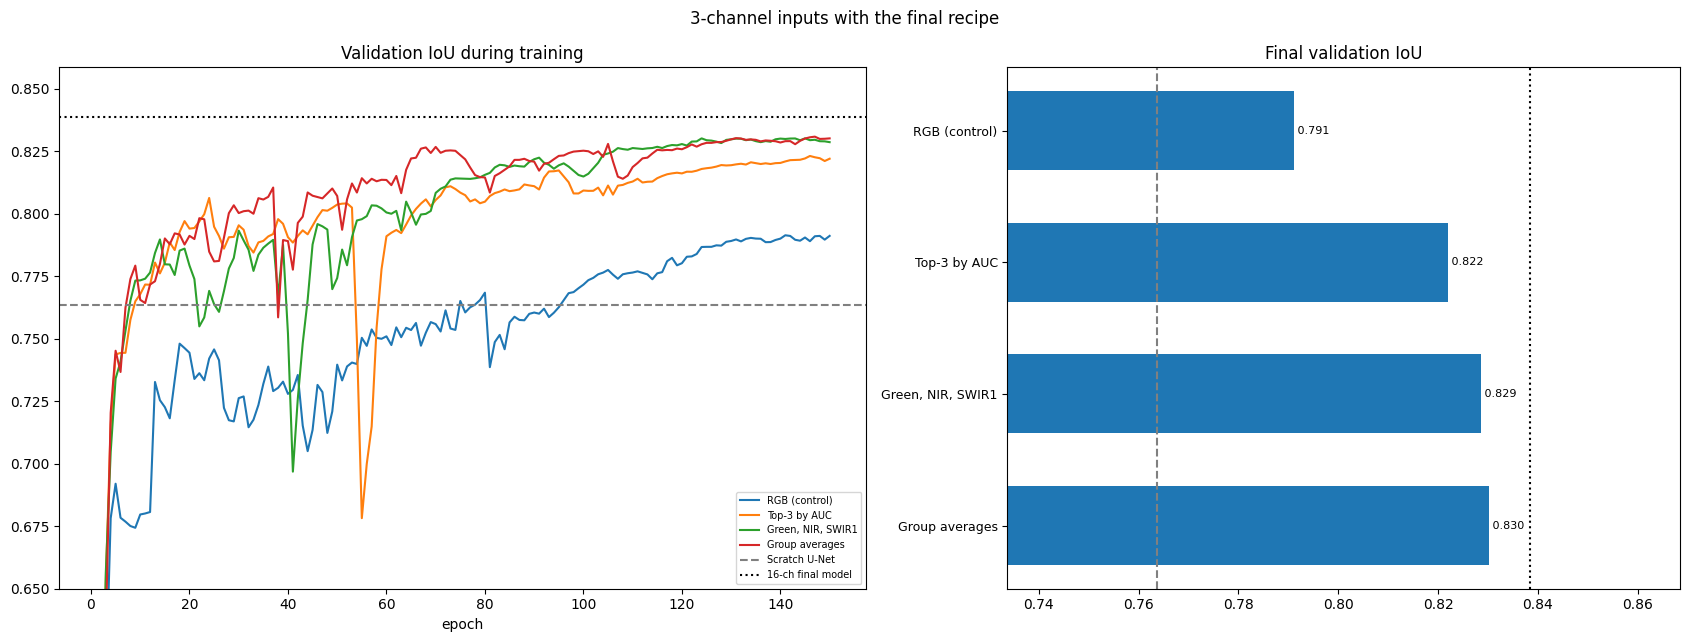

best input: Group averages -> ['Visible mean', 'NIR', 'SWIR mean'] | val IoU 0.8301
16-channel reference val IoU 0.8385


In [10]:
stage1 = {}
for inp in INPUTS:
    stage1[inp["name"]] = train({**FINAL_CFG, **inp}, FINAL_RECIPE, inp["name"])
    print("channels:", inp["channels"], "\n")

plot_stage(stage1, "3-channel inputs with the final recipe")
best_label = max(stage1, key=lambda k: stage1[k]["val"]["iou"])
final = stage1[best_label]
print("best input:", best_label, "->", final["cfg"]["channels"], f"| val IoU {final['val']['iou']:.4f}")
print(f"16-channel reference val IoU {REFERENCE_16CH['val']['iou']:.4f}")

## 11. Final model: training trace

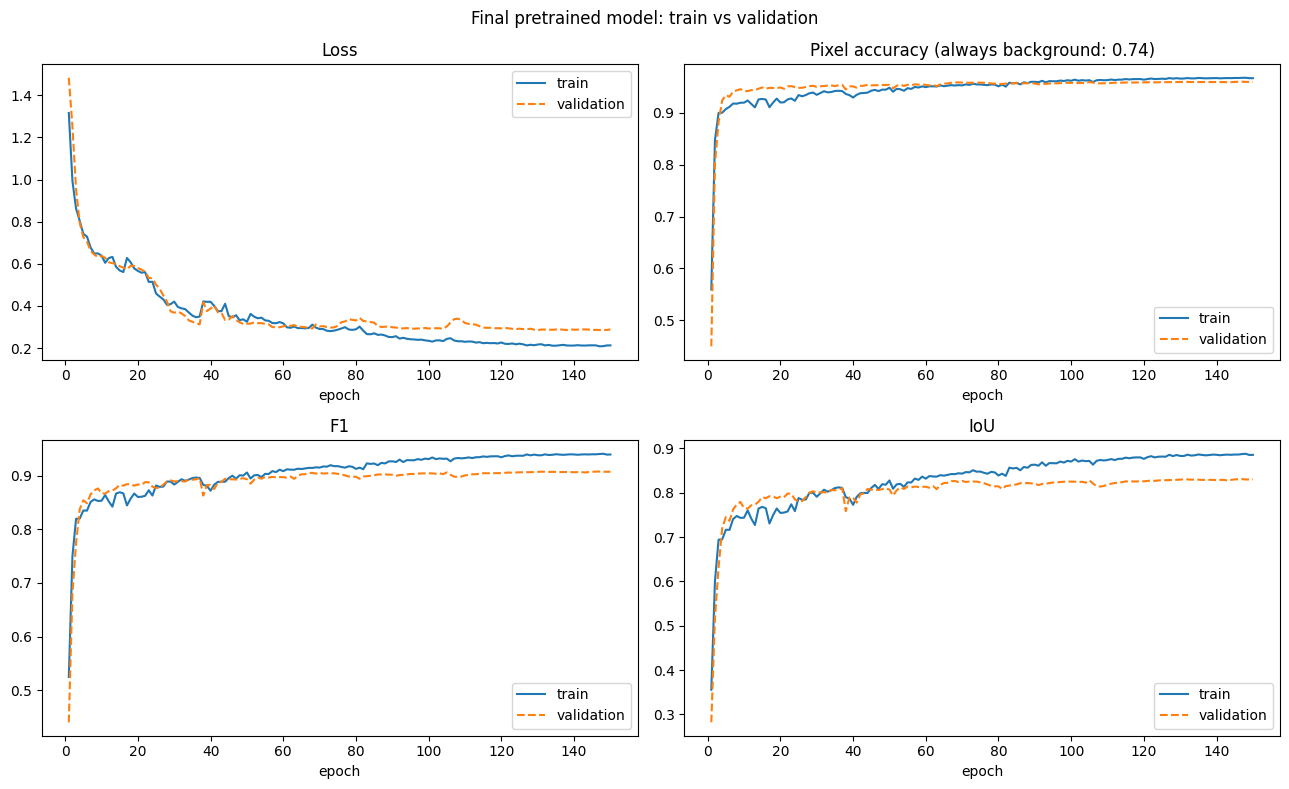

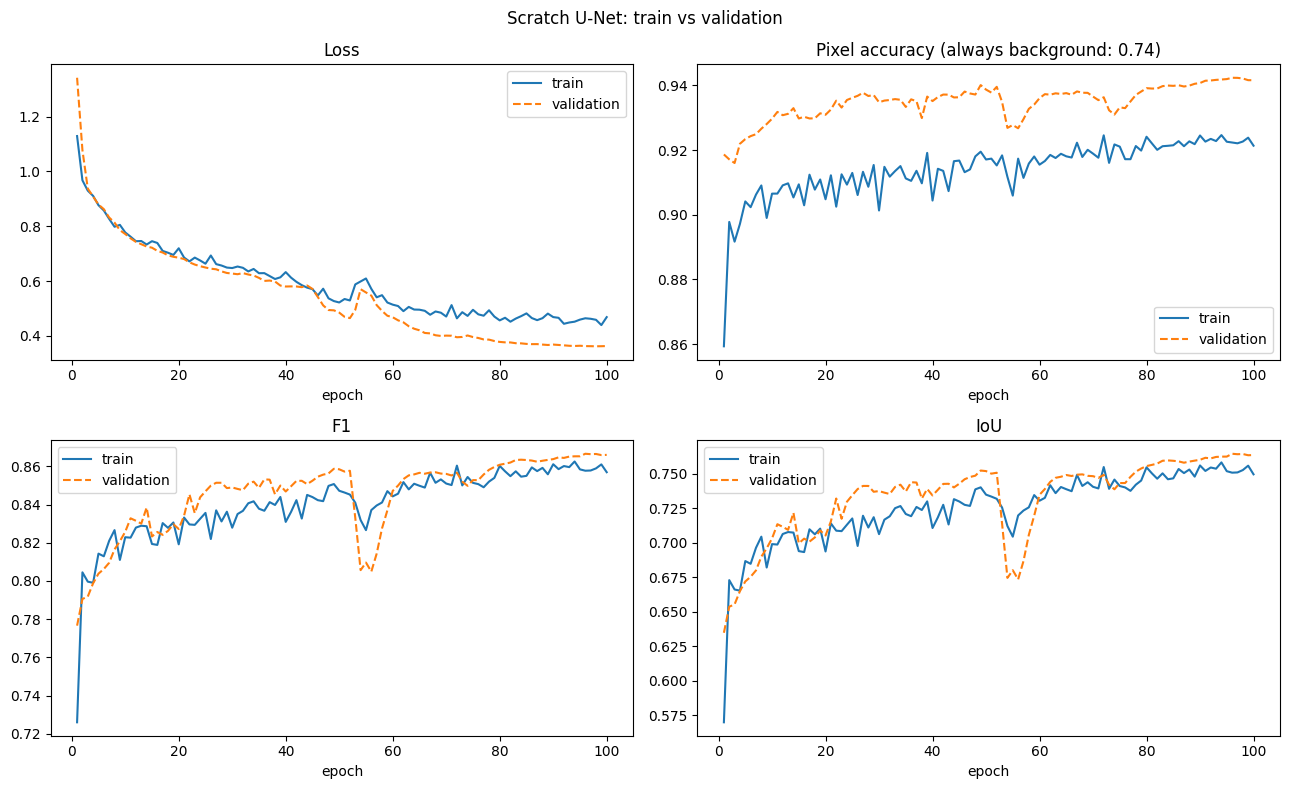

In [11]:
plot_trace(final, "Final pretrained model: train vs validation")
plot_trace(scratch, "Scratch U-Net: train vs validation")

## 12. Test-time augmentation and seed stability

In [12]:
def predict_tta(model, indices, channels):
    x = torch.from_numpy(X[np.ix_(indices, channels)])
    total = 0
    for flip in (False, True):
        for k in range(4):
            t = torch.rot90(x.flip(3) if flip else x, k, (2, 3))
            p = torch.rot90(torch.from_numpy(predict_tensor(model, t)), -k, (1, 2))
            total = total + (p.flip(2) if flip else p)
    return (total / 8).numpy()


final_tta = metrics(predict_tta(final["model"], val_idx, final["channels"]), gt_val)

seed_runs = [final] + [train(final["cfg"], final["recipe"], f"seed {sd}", sd) for sd in SEEDS_EXTRA]
v = [r["val"]["iou"] for r in seed_runs]
print(f"validation IoU over {len(seed_runs)} seeds: {np.mean(v):.4f} ± {np.std(v):.4f}")

seed 43 | epoch   1 | train loss 1.222 acc 0.733 F1 0.607 | val loss 1.462 acc 0.708 F1 0.587 IoU 0.415
seed 43 | epoch  25 | train loss 0.538 acc 0.923 F1 0.854 | val loss 0.444 acc 0.947 F1 0.879 IoU 0.784
seed 43 | epoch  50 | train loss 0.325 acc 0.946 F1 0.903 | val loss 0.339 acc 0.952 F1 0.889 IoU 0.801
seed 43 | epoch  75 | train loss 0.293 acc 0.954 F1 0.916 | val loss 0.329 acc 0.958 F1 0.901 IoU 0.820
seed 43 | epoch 100 | train loss 0.247 acc 0.960 F1 0.927 | val loss 0.301 acc 0.957 F1 0.902 IoU 0.821
seed 43 | epoch 125 | train loss 0.224 acc 0.964 F1 0.934 | val loss 0.285 acc 0.959 F1 0.907 IoU 0.830
seed 43 | epoch 150 | train loss 0.216 acc 0.965 F1 0.937 | val loss 0.290 acc 0.959 F1 0.907 IoU 0.829
seed 43 | final epoch | val IoU 0.8294 | val F1 0.9067

seed 44 | epoch   1 | train loss 1.194 acc 0.777 F1 0.628 | val loss 1.311 acc 0.801 F1 0.583 IoU 0.411
seed 44 | epoch  25 | train loss 0.464 acc 0.925 F1 0.868 | val loss 0.509 acc 0.942 F1 0.867 IoU 0.766
seed 44 

## 13. Comparison with the scratch U-Net and the 16-channel model

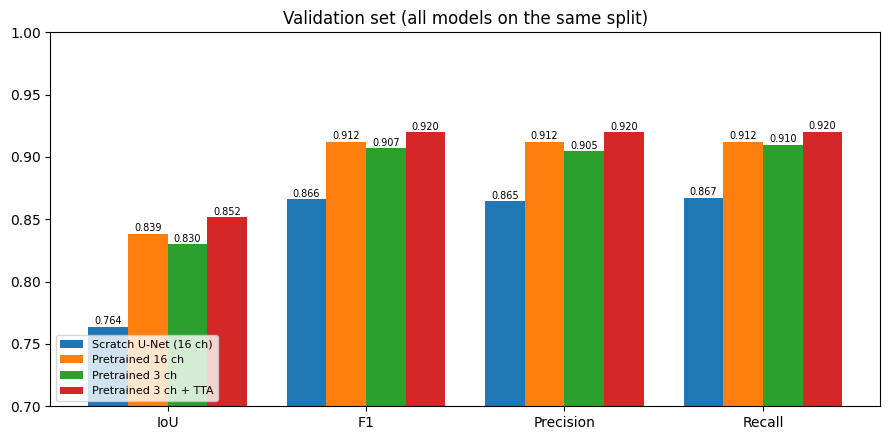

validation IoU 0.8301 vs scratch U-Net 0.7637 (delta +0.0665), higher than scratch U-Net: yes

validation IoU 0.8301 vs the 16-channel model 0.8385 (delta -0.0084); with TTA 0.8518 vs 0.8512

| Model | Val IoU | Val F1 | Val Precision | Val Recall |
|---|---|---|---|---|
| Scratch U-Net (16 ch) | 0.7637 | 0.8660 | 0.8646 | 0.8674 |
| Pretrained 16 ch | 0.8385 | 0.9122 | 0.9121 | 0.9123 |
| Pretrained 3 ch | 0.8301 | 0.9072 | 0.9046 | 0.9098 |
| Pretrained 3 ch + TTA | 0.8518 | 0.9200 | 0.9198 | 0.9201 |


In [13]:
models = {"Scratch U-Net (16 ch)": scratch["val"], "Pretrained 16 ch": REFERENCE_16CH["val"],
          "Pretrained 3 ch": final["val"], "Pretrained 3 ch + TTA": final_tta}
keys = ["iou", "f1", "precision", "recall"]

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.8 / len(models)
for i, (name, m) in enumerate(models.items()):
    vals = [m[k] for k in keys]
    bars = ax.bar(np.arange(4) + i * width - 0.4 + width / 2, vals, width, label=name, color=COLORS[i])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=7)
ax.set_xticks(range(4))
ax.set_xticklabels(["IoU", "F1", "Precision", "Recall"])
ax.set_ylim(0.7, 1.0)
ax.set_title("Validation set (all models on the same split)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

delta = final["val"]["iou"] - scratch["val"]["iou"]
print(f"validation IoU {final['val']['iou']:.4f} vs scratch U-Net {scratch['val']['iou']:.4f} (delta {delta:+.4f}), higher than scratch U-Net: {'yes' if delta > 0 else 'no'}\n")
delta_ref = final["val"]["iou"] - REFERENCE_16CH["val"]["iou"]
print(f"validation IoU {final['val']['iou']:.4f} vs the 16-channel model {REFERENCE_16CH['val']['iou']:.4f} (delta {delta_ref:+.4f}); with TTA {final_tta['iou']:.4f} vs {REFERENCE_16CH['tta']['iou']:.4f}\n")

print("| Model | Val IoU | Val F1 | Val Precision | Val Recall |\n|---|---|---|---|---|")
for name, m in models.items():
    print(f"| {name} | " + " | ".join(f"{m[k]:.4f}" for k in keys) + " |")

## 14. Analysis of the final model

  0%|          | 0/3 [00:00<?, ?it/s]

validation IoU 0.8301 | the final input has no ancillary channels, so there is nothing to zero


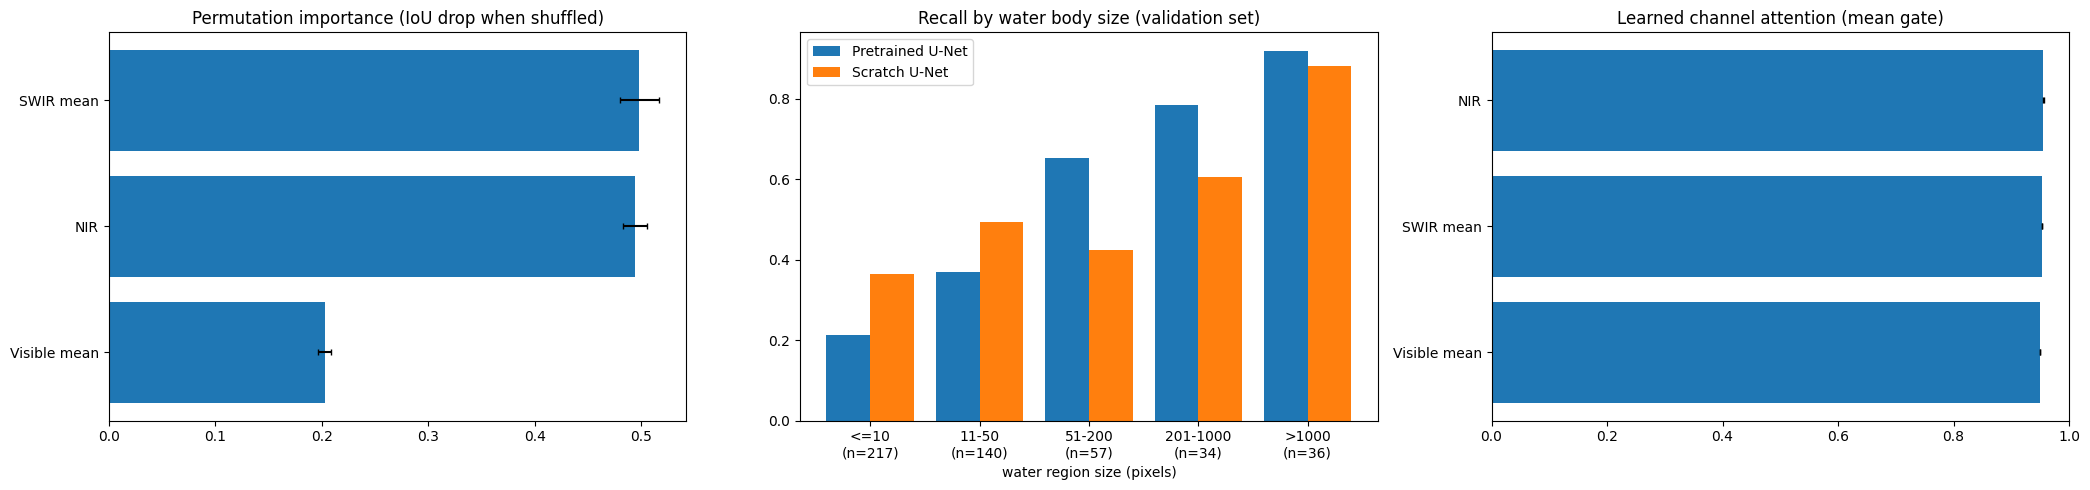

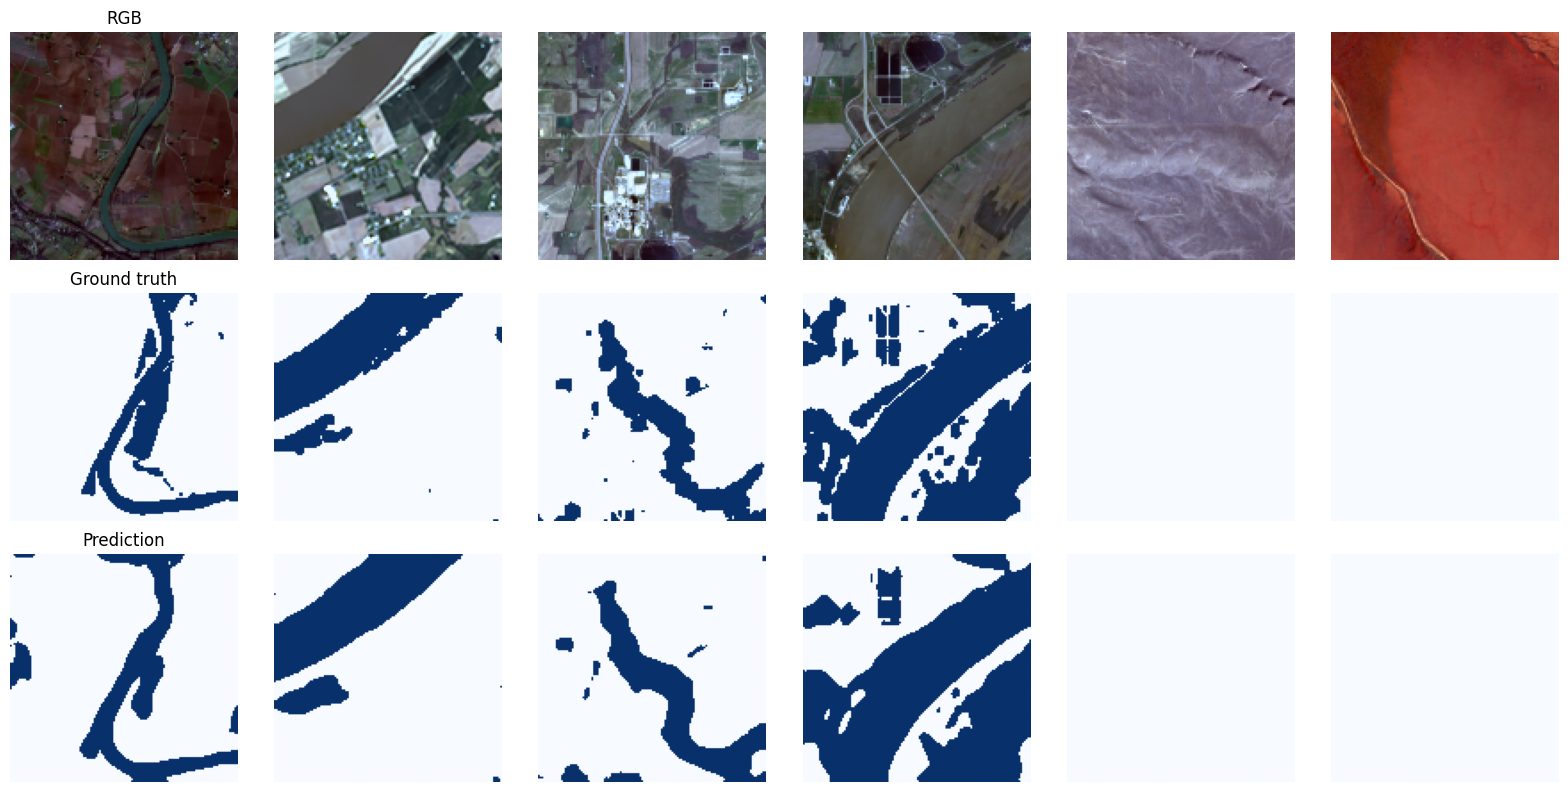

selected channels: ['Visible mean', 'NIR', 'SWIR mean']


In [14]:
channels = final["channels"]
names = [NAMES[c] for c in channels]
x = torch.from_numpy(X[np.ix_(val_idx, channels)])

base_iou = metrics(predict_tensor(final["model"], x), gt_val)["iou"]
g = torch.Generator().manual_seed(0)
drops = np.zeros((len(channels), 3))
for j in tqdm(range(len(channels))):
    for r in range(3):
        xp = x.clone()
        xp[:, j] = x[torch.randperm(len(x), generator=g), j]
        drops[j, r] = base_iou - metrics(predict_tensor(final["model"], xp), gt_val)["iou"]

anc_cols = [j for j, c in enumerate(channels) if NAMES[c] in ANCILLARY]
if anc_cols:
    xz = x.clone()
    xz[:, anc_cols] = 0
    print(f"validation IoU {base_iou:.4f} | with the ancillary channels {[names[j] for j in anc_cols]} zeroed {metrics(predict_tensor(final['model'], xz), gt_val)['iou']:.4f}")
else:
    print(f"validation IoU {base_iou:.4f} | the final input has no ancillary channels, so there is nothing to zero")


def recall_by_size(prob):
    pred = prob > 0.5
    sizes, recalls = [], []
    for i in range(len(gt_val)):
        lab, n = cc_label(gt_val[i])
        for k in range(1, n + 1):
            region = lab == k
            sizes.append(int(region.sum()))
            recalls.append(pred[i][region].mean())
    ids = np.digitize(np.array(sizes), [10, 50, 200, 1000], right=True)
    recalls = np.array(recalls)
    return [recalls[ids == b].mean() if (ids == b).any() else 0 for b in range(5)], [int((ids == b).sum()) for b in range(5)]


rec_final, counts = recall_by_size(final["pv"])
rec_scratch, _ = recall_by_size(scratch["pv"])
size_labels = ["<=10", "11-50", "51-200", "201-1000", ">1000"]

n_panels = 3 if final["recipe"]["attention"] else 2
fig, axes = plt.subplots(1, n_panels, figsize=(7 * n_panels, 5))
order = np.argsort(drops.mean(1))
axes[0].barh([names[i] for i in order], drops.mean(1)[order], xerr=drops.std(1)[order], capsize=2)
axes[0].set_title("Permutation importance (IoU drop when shuffled)")

axes[1].bar(np.arange(5) - 0.2, rec_final, 0.4, label="Pretrained U-Net")
axes[1].bar(np.arange(5) + 0.2, rec_scratch, 0.4, label="Scratch U-Net")
axes[1].set_xticks(range(5))
axes[1].set_xticklabels([f"{l}\n(n={c})" for l, c in zip(size_labels, counts)])
axes[1].set_xlabel("water region size (pixels)")
axes[1].set_title("Recall by water body size (validation set)")
axes[1].legend()

if final["recipe"]["attention"]:
    with torch.no_grad():
        final["model"].eval()
        w = torch.cat([final["model"].attn.fc(b.to(device).mean(dim=(2, 3))).cpu() for b in x.split(BATCH_SIZE)]).numpy()
    order = np.argsort(w.mean(0))
    axes[2].barh([names[i] for i in order], w.mean(0)[order], xerr=w.std(0)[order], capsize=2)
    axes[2].set_xlim(0, 1)
    axes[2].set_title("Learned channel attention (mean gate)")
plt.tight_layout()
plt.show()

xb, yb = next(iter(make_loader(val_idx[:6], channels, False)))
pred = predict_tensor(final["model"], xb) > 0.5
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for j in range(len(xb)):
    rgb = X[val_idx[j], [3, 2, 1]].transpose(1, 2, 0)
    axes[0, j].imshow((rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6))
    axes[1, j].imshow(yb[j, 0], cmap="Blues")
    axes[2, j].imshow(pred[j], cmap="Blues")
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].set_title("RGB")
axes[1, 0].set_title("Ground truth")
axes[2, 0].set_title("Prediction")
plt.tight_layout()
plt.show()

torch.save(final["model"].state_dict(), "best_pretrained_model_3ch.pt")
pd.concat({n: r["history"] for n, r in {"scratch U-Net": scratch, **stage1}.items()}, names=["model"]).to_csv("training_histories_3ch.csv")
json.dump({"channels": [NAMES[c] for c in final["channels"]], "cfg": final["cfg"], "recipe": final["recipe"]}, open("selected_channels_3ch.json", "w"), indent=2)
print("selected channels:", [NAMES[c] for c in final["channels"]])

## Notes for reading the results

- The recipe (ResNet50, Tversky loss, attention, EMA, 2x upscaling) was selected on the 16-channel inputs and is not re-tuned here. A different recipe might suit 3 channels better. Channel attention over only 3 channels is a small gate and could be ablated in a follow-up.
- Validation IoU picks the input and reports the score, so the numbers are slightly optimistic, as in the 16-channel run. Differences of a few thousandths are within seed noise (Section 12).
- The 16-channel model and the scratch U-Net use more inputs than this model, so gaps to them reflect both the number of channels and the first-layer change.
- `selected_channels_3ch.json` records the final input channels for the deployment code.